In [17]:
# 1. Reproducibility
np.random.seed(42)
tf.random.set_seed(42)

In [18]:
# 2. Load the public MNIST dataset
(X_train, y_train), (X_test, y_test) = (
    tf.keras.datasets.mnist.load_data()
)

print("Training images:", X_train.shape)
print("Testing images:", X_test.shape)


Training images: (60000, 28, 28)
Testing images: (10000, 28, 28)


In [19]:
# 3. Preprocess the images
# Convert pixel values from 0-255 to 0-1
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

# Add a channel dimension for CNN input
X_train = X_train[..., np.newaxis]
X_test = X_test[..., np.newaxis]

print("Processed training shape:", X_train.shape)

Processed training shape: (60000, 28, 28, 1)


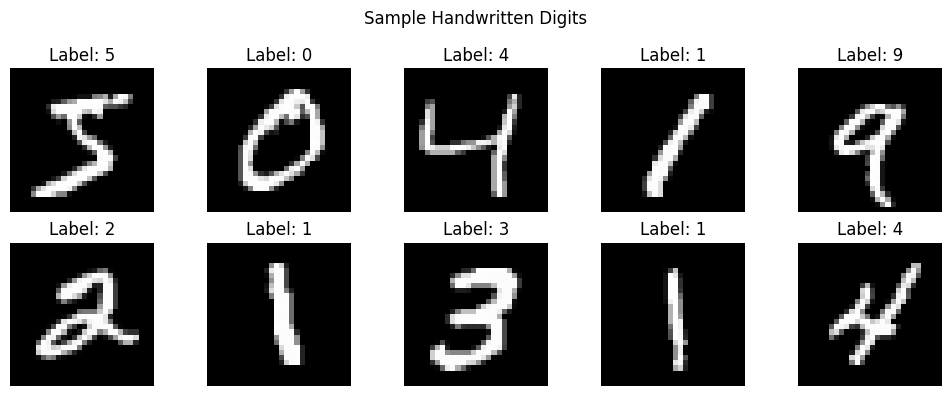

In [20]:
# 4. Display sample images
plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i].squeeze(), cmap="gray")
    plt.title(f"Label: {y_train[i]}")
    plt.axis("off")

plt.suptitle("Sample Handwritten Digits")
plt.tight_layout()
plt.show()

In [24]:
# 5. Design the CNN model
model = models.Sequential([
    layers.Input(shape=(28, 28, 1)),

    # Learn local image patterns
    layers.Conv2D(
        32, kernel_size=(3, 3),
        activation="relu"
    ),
    layers.MaxPooling2D(pool_size=(2, 2)),

    # Learn more complex patterns
    layers.Conv2D(
        64, kernel_size=(3, 3),
        activation="relu"
    ),
    layers.MaxPooling2D(pool_size=(2, 2)),

    # Convert feature maps into a vector
    layers.Flatten(),

    # Fully connected classification layer
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.30),

    # Output probabilities for digits 0-9
    layers.Dense(10, activation="softmax")
])


In [25]:
# 6. Configure training
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Display architecture and parameter counts
model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_10 (Conv2D)              │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_5 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

In [27]:
# 7. Prevent unnecessary training and reduce overfitting
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

In [28]:
# 8. Train the model
history = model.fit(
    X_train,
    y_train,
    epochs=15,
    batch_size=128,
    validation_split=0.10,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 38s 88ms/step - accuracy: 0.9025 - loss: 0.3262 - val_accuracy: 0.9817 - val_loss: 0.0635
Epoch 2/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 37s 87ms/step - accuracy: 0.9694 - loss: 0.1019 - val_accuracy: 0.9847 - val_loss: 0.0518
Epoch 3/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 38s 89ms/step - accuracy: 0.9768 - loss: 0.0760 - val_accuracy: 0.9880 - val_loss: 0.0419
Epoch 4/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 35s 84ms/step - accuracy: 0.9814 - loss: 0.0609 - val_accuracy: 0.9892 - val_loss: 0.0387
Epoch 5/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 42s 87ms/step - accuracy: 0.9842 - loss: 0.0507 - val_accuracy: 0.9902 - val_loss: 0.0386
Epoch 6/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 37s 87ms/step - accuracy: 0.9864 - loss: 0.0439 - val_accuracy: 0.9895 - val_loss: 0.0355
Epoch 7/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 41s 86ms/step - accuracy: 0.9878 - loss: 0.0396 - val_accuracy: 0.9910 - val_loss: 0.0371
Epoch 8/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 35s 83ms/step - accuracy: 0.9894 - loss: 0.0337 - 

In [29]:
# 9. Evaluate on unseen test images
test_loss, test_accuracy = model.evaluate(
    X_test, y_test, verbose=0
)

print("\nTest Loss:", round(test_loss, 4))
print("Test Accuracy:", f"{test_accuracy * 100:.2f}%")


Test Loss: 0.0273
Test Accuracy: 99.12%


In [30]:
# 10. Generate predictions
probabilities = model.predict(X_test, verbose=0)
y_pred = np.argmax(probabilities, axis=1)

print("\nClassification Report:")
print(classification_report(y_test, y_pred, digits=4))


Classification Report:
              precision    recall  f1-score   support

           0     0.9980    0.9939    0.9959       980
           1     0.9956    0.9974    0.9965      1135
           2     0.9913    0.9884    0.9898      1032
           3     0.9950    0.9851    0.9900      1010
           4     0.9929    0.9949    0.9939       982
           5     0.9801    0.9922    0.9861       892
           6     0.9958    0.9896    0.9927       958
           7     0.9846    0.9932    0.9889      1028
           8     0.9847    0.9918    0.9882       974
           9     0.9930    0.9851    0.9891      1009

    accuracy                         0.9912     10000
   macro avg     0.9911    0.9911    0.9911     10000
weighted avg     0.9912    0.9912    0.9912     10000



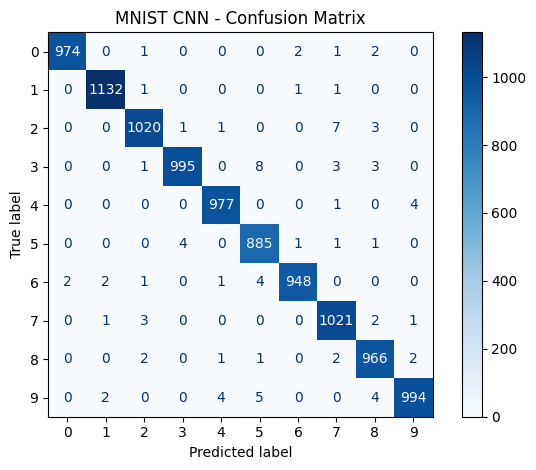

In [31]:
# 11. Plot the confusion matrix
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=np.arange(10)
)

disp.plot(cmap="Blues", values_format="d")
plt.title("MNIST CNN - Confusion Matrix")
plt.tight_layout()
plt.show()

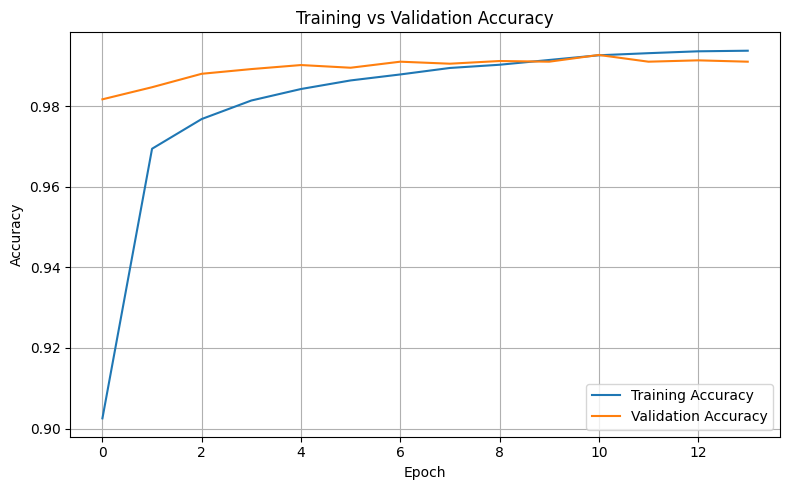

In [32]:
# 12. Plot training and validation accuracy
plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

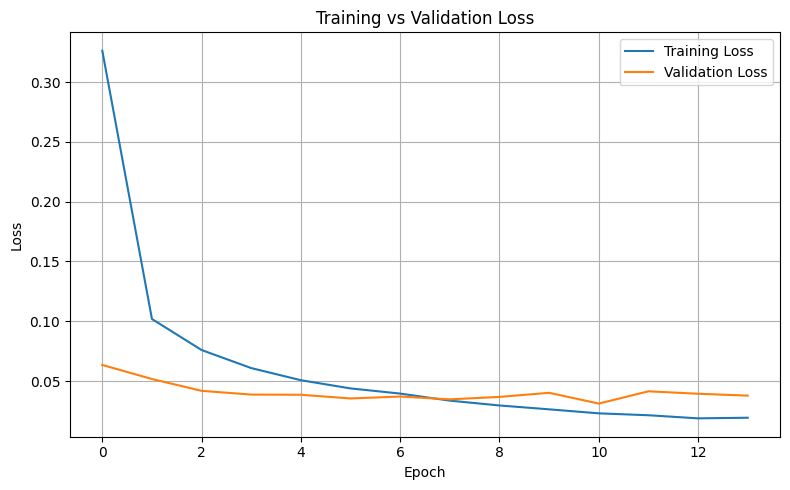

In [33]:
# 13. Plot training and validation loss
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

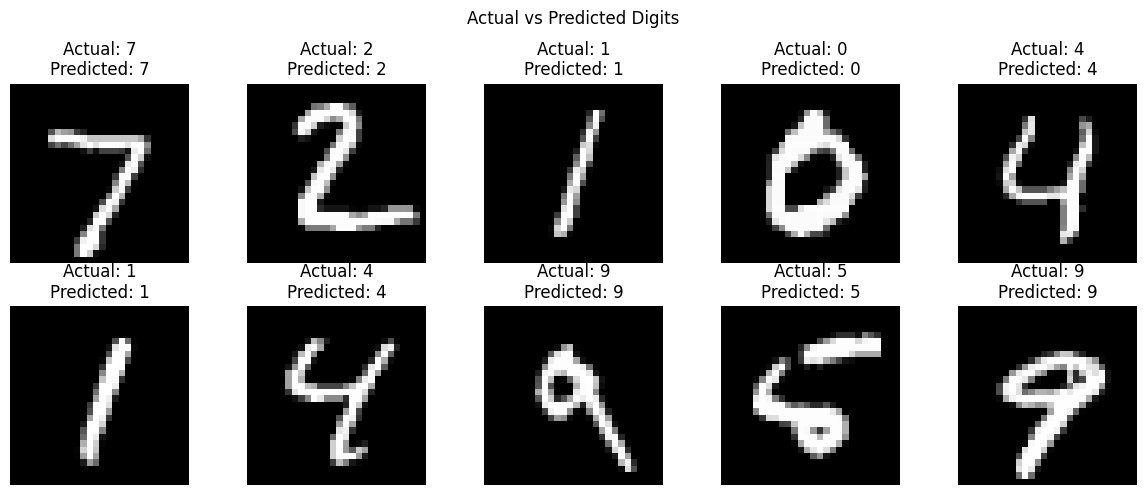

In [34]:

# 14. Display sample predictions
plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test[i].squeeze(), cmap="gray")

    actual = y_test[i]
    predicted = y_pred[i]

    plt.title(f"Actual: {actual}\nPredicted: {predicted}")
    plt.axis("off")

plt.suptitle("Actual vs Predicted Digits")
plt.tight_layout()
plt.show()


In [35]:
# 15. Save the trained model
model.save("week5_mnist_cnn.keras")

print("\nModel saved as week5_mnist_cnn.keras")



Model saved as week5_mnist_cnn.keras
